<center><h1>Jha_Ria_HW6</h1></center>


Name: Ria Jha
<br>
Github Username: riajha-usc
<br>
USC ID: 8116906970


## 1. Tree-Based Methods


Import packages


In [1]:
import sys
print(sys.executable)
!{sys.executable} -m pip install xgboost imbalanced-learn

/usr/local/bin/python3.12

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import os
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
warnings.filterwarnings("ignore")

### (a) Download the APS Failure data


In [3]:
ZIP_PATH = "Homework 6 Data.zip"
DATA_DIR = "Homework 6 Data"
with zipfile.ZipFile(ZIP_PATH) as zf:
    members = [m for m in zf.namelist() if not m.startswith("__MACOSX") and m.strip("/")]
    zf.extractall(DATA_DIR, members=members)

train = pd.read_csv(os.path.join(DATA_DIR, "aps_failure_training_set.csv"), skiprows=20, na_values="na")
test = pd.read_csv(os.path.join(DATA_DIR, "aps_failure_test_set.csv"), skiprows=20, na_values="na")
y_train = (train["class"] == "pos").astype(int).values
y_test = (test["class"] == "pos").astype(int).values
X_train_raw = train.drop(columns="class")
X_test_raw = test.drop(columns="class")
print(train.shape, test.shape)
print(X_train_raw.isna().mean().sort_values(ascending=False).head(8).round(3))
print("Rows with at least one missing value:", round(X_train_raw.isna().any(axis=1).mean(), 3))

(60000, 171) (16000, 171)
br_000    0.821
bq_000    0.812
bp_000    0.796
bo_000    0.772
cr_000    0.772
ab_000    0.772
bn_000    0.733
bm_000    0.659
dtype: float64
Rows with at least one missing value: 0.99


### (b) Data Preparation


#### (i) Research what types of techniques are usually used


To handle missing values are:

1. dropping rows or columns with missing entries
2. mean or median imputation
3. KNN imputation
4. iterative or model-based imputation such as MICE
5. adding missing-value indicator columns.

Dropping is not workable here, because 99% of the rows have at least one missing value and some features are missing 66% to 82% of their values. I used median imputation, because the features are heavily skewed with large outliers and the median is robust to them. The median is learned on the training set only and applied to both the training and test sets.


In [4]:
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X_train_raw.columns)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns)
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

0 0


#### (ii) Calculate the coefficient of variation


In [5]:
cv = (X_train.std(ddof=1) / X_train.mean()).abs().replace([np.inf, -np.inf], np.nan).dropna().sort_values(ascending=False)
print(cv.head(15))

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
cr_000     58.078072
ay_001     52.824714
dtype: float64


The coefficient of variation is the sample standard deviation divided by the mean. The largest values are cf_000 (244.9), co_000 (244.5), ad_000 (244.3), cs_009 (237.9) and dh_000 (123.2). These features are zero for most trucks and very large for a few.


#### (iii) Plot a correlation matrix


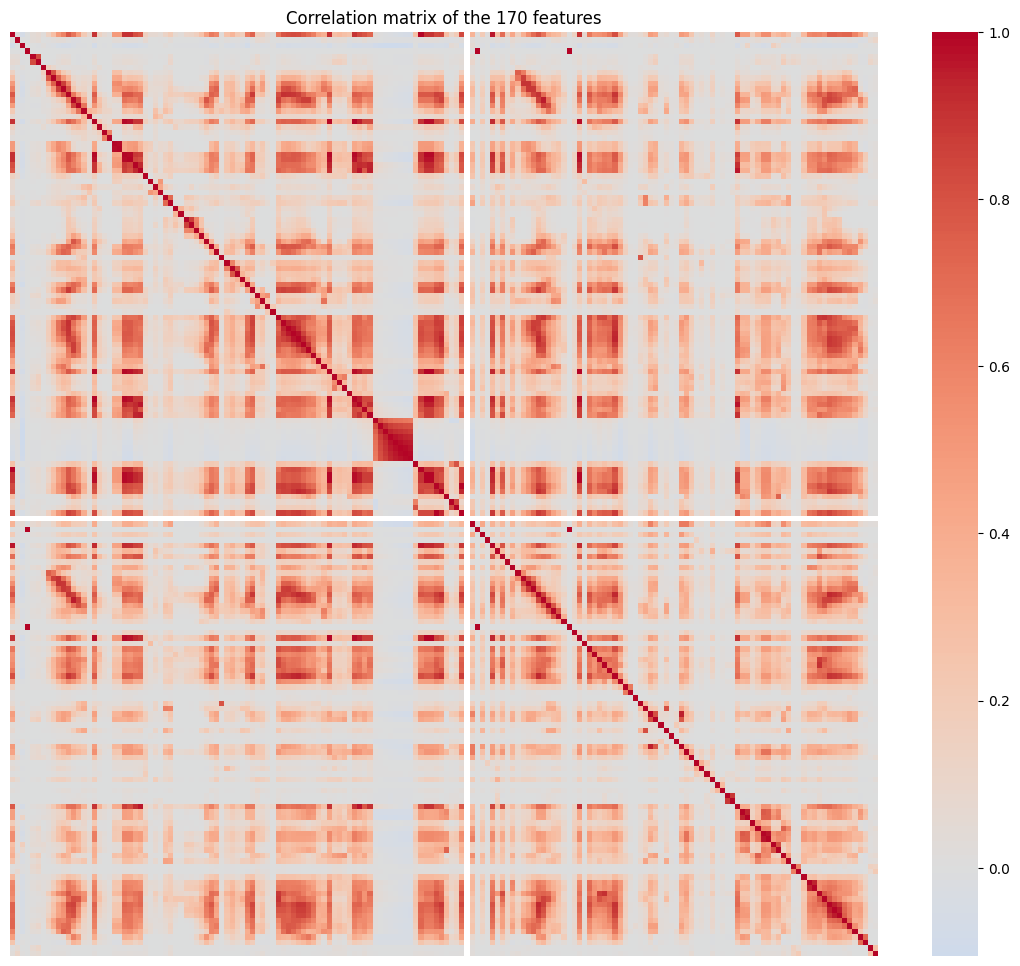

Feature pairs with |r| > 0.9: 130


In [6]:
corr = X_train.corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Correlation matrix of the 170 features")
plt.show()
print("Feature pairs with |r| > 0.9:", int((corr.abs().values[np.triu_indices_from(corr, 1)] > 0.9).sum()))

The matrix shows many groups of strongly correlated features, with 130 feature pairs above |r| = 0.9. Many of these are probably related counters and histogram bins of the same sensor, so the features carry redundant information.


#### (iv) Make scatter plots and box plots


13 ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


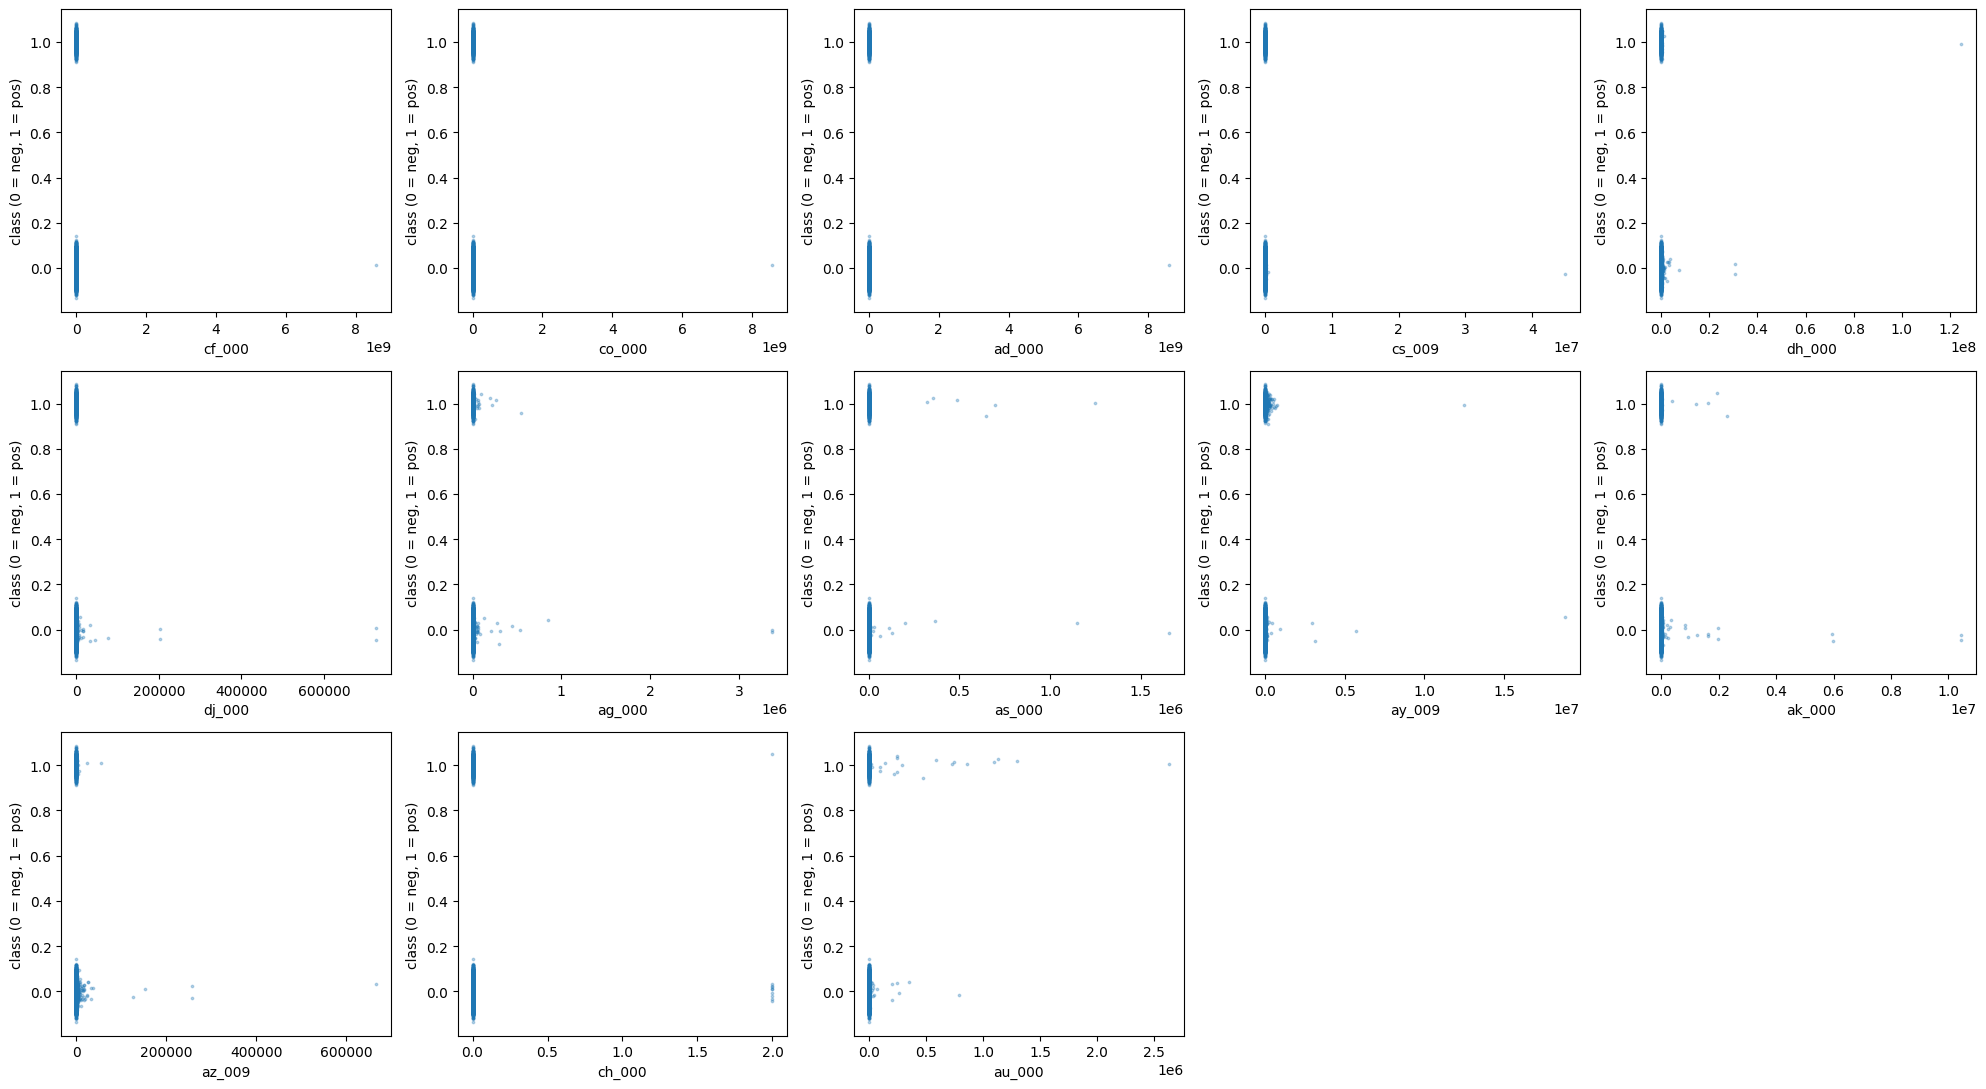

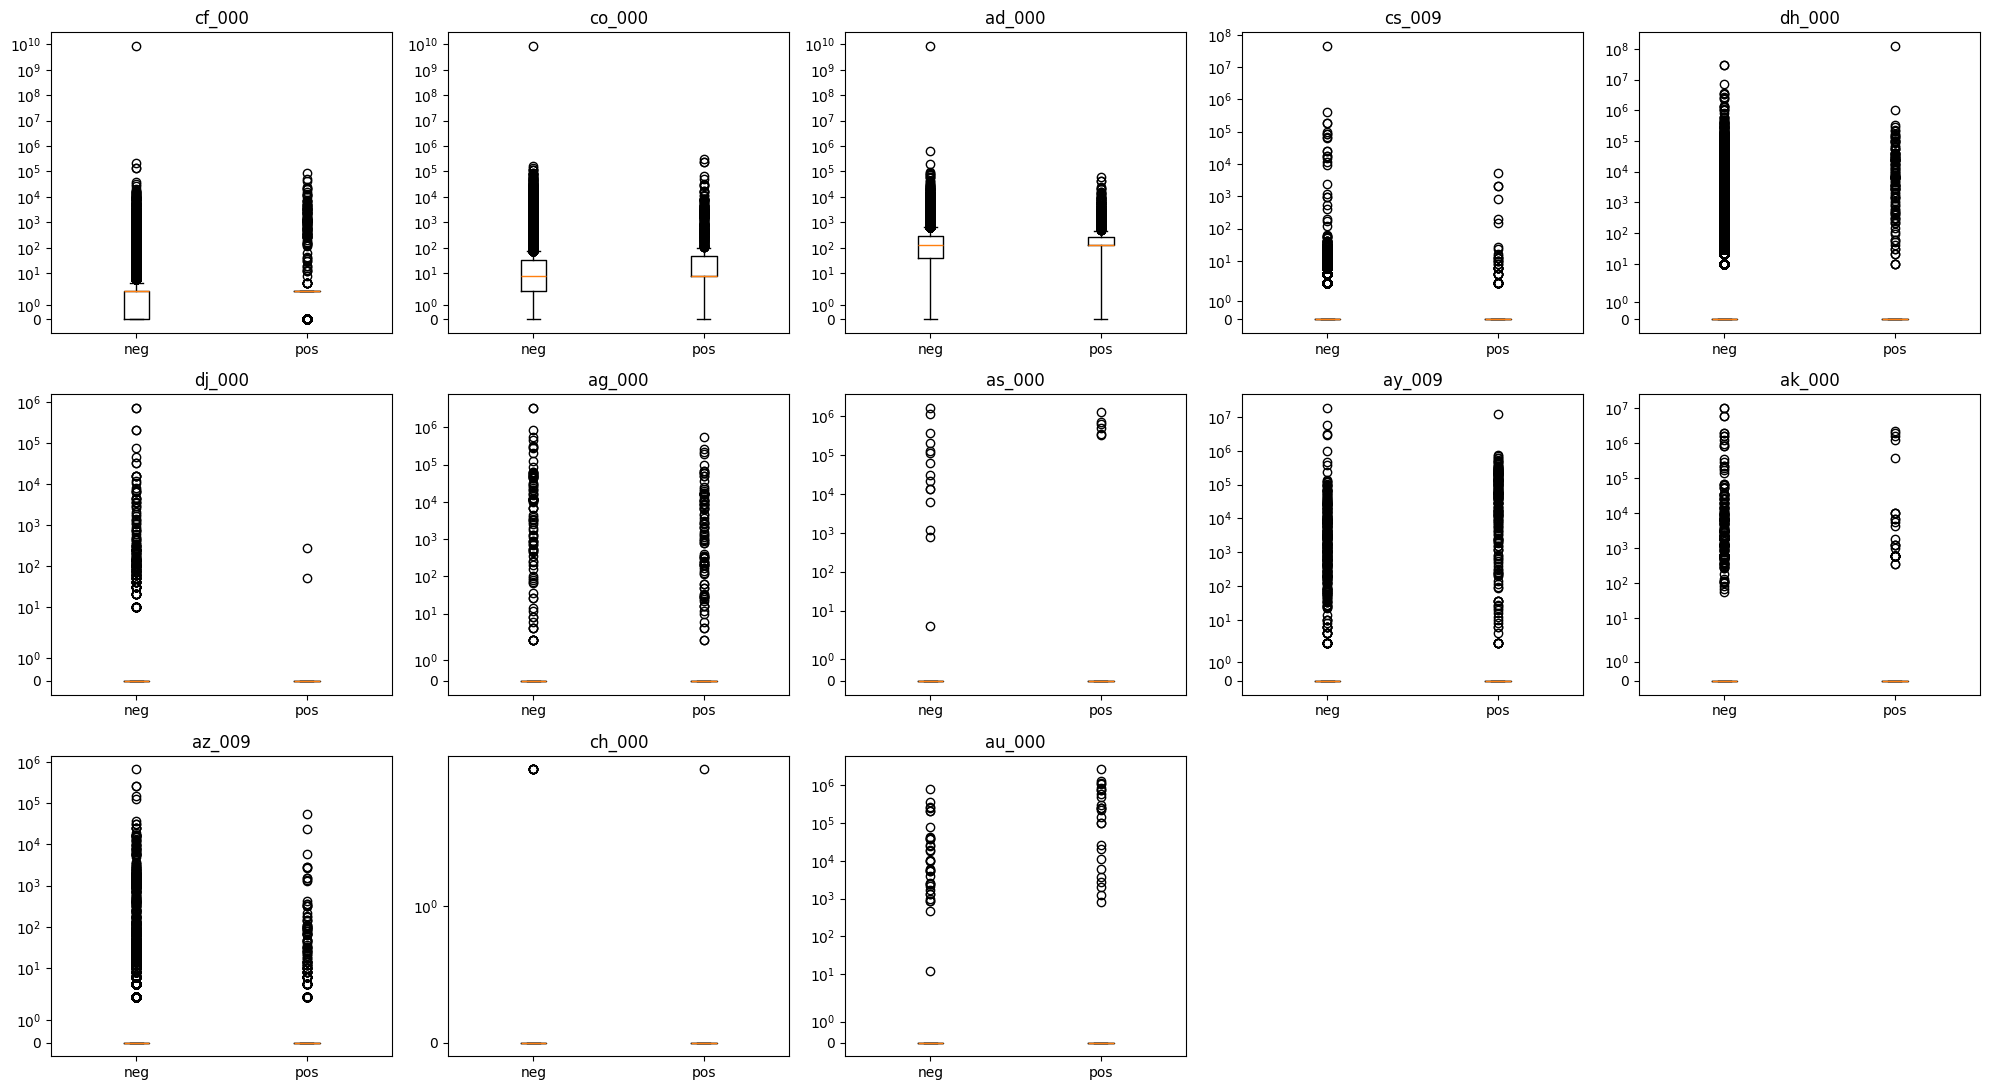

In [7]:
k = int(np.floor(np.sqrt(170)))
top_cv = cv.index[:k].tolist()
print(k, top_cv)
rng = np.random.default_rng(0)
jit = y_train + rng.normal(0, 0.03, size=len(y_train))

fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, c in zip(axes.ravel(), top_cv):
    ax.scatter(X_train[c], jit, s=3, alpha=0.3)
    ax.set_xlabel(c); ax.set_ylabel("class (0 = neg, 1 = pos)")
for ax in axes.ravel()[len(top_cv):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, c in zip(axes.ravel(), top_cv):
    ax.boxplot([X_train[c][y_train == 0], X_train[c][y_train == 1]])
    ax.set_xticklabels(["neg", "pos"])
    ax.set_title(c); ax.set_yscale("symlog")
for ax in axes.ravel()[len(top_cv):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

The 13 features with the highest CV are cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000 and au_000. The scatter plots against the class and the box plots by class show most values near zero with a few very large outliers, so I used a symlog axis. The two classes overlap heavily, so I cannot conclude from these plots alone that any feature is significant. A scatter plot gives no test statistic, and a high CV only says the feature varies a lot, not that it separates the classes.


#### (v) Is this data set imbalanced?


In [8]:
print("Training  : negative =", int((y_train == 0).sum()), "| positive =", int((y_train == 1).sum()), "| positive share =", round(y_train.mean(), 4))
print("Test      : negative =", int((y_test == 0).sum()), "| positive =", int((y_test == 1).sum()), "| positive share =", round(y_test.mean(), 4))

Training  : negative = 59000 | positive = 1000 | positive share = 0.0167
Test      : negative = 15625 | positive = 375 | positive share = 0.0234


The training set has 59,000 negative and 1,000 positive examples (1.67% positive), and the test set has 15,625 negative and 375 positive (2.34% positive). The data set is strongly imbalanced. A classifier that always predicts negative would be 98.3% accurate, so accuracy alone is misleading here.


### (c) Train a random forest


Random forest | Train: AUC = 1.0000 | misclassification = 0.0000
          pred neg  pred pos
true neg     59000         0
true pos         0      1000
Random forest | Test: AUC = 0.9944 | misclassification = 0.0075
          pred neg  pred pos
true neg     15607        18
true pos       102       273


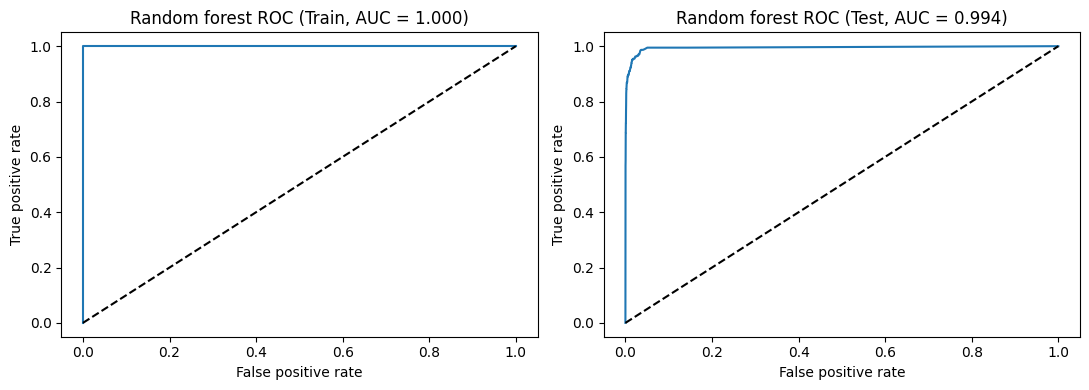

OOB error estimate: 0.0058 | test error: 0.0075


In [9]:
def evaluate(model, name):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    out = {}
    for (label, X, y) in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        pred = model.predict(X)
        prob = model.predict_proba(X)[:, 1]
        auc = roc_auc_score(y, prob)
        err = 1 - accuracy_score(y, pred)
        print(f"{name} | {label}: AUC = {auc:.4f} | misclassification = {err:.4f}")
        print(pd.DataFrame(confusion_matrix(y, pred), index=["true neg", "true pos"], columns=["pred neg", "pred pos"]))
        fpr, tpr, _ = roc_curve(y, prob)
        a = ax[0 if label == "Train" else 1]
        a.plot(fpr, tpr)
        a.plot([0, 1], [0, 1], "k--")
        a.set_title(f"{name} ROC ({label}, AUC = {auc:.3f})")
        a.set_xlabel("False positive rate"); a.set_ylabel("True positive rate")
        out[label] = (auc, err)
    plt.tight_layout(); plt.show()
    return out

rf = RandomForestClassifier(n_estimators=300, oob_score=True, n_jobs=-1, random_state=0)
rf.fit(X_train, y_train)
rf_res = evaluate(rf, "Random forest")
print("OOB error estimate:", round(1 - rf.oob_score_, 4), "| test error:", round(rf_res["Test"][1], 4))

I trained a random forest with 300 trees and no compensation for imbalance. On the training set it gets AUC = 1.0 and 0 errors, since a forest of fully grown trees can memorize the training data. On the test set the AUC is 0.9944 and the misclassification rate is 0.0075 (15,607 true negatives, 18 false positives, 102 false negatives, 273 true positives). The OOB error estimate is 0.0058, a bit lower than the test error of 0.0075, so OOB is a close but slightly optimistic estimate. The test set also has a higher share of positives (2.3% vs 1.7%), which makes it a little harder. The forest finds only 273 of the 375 failures (recall 73%), which is the effect of the imbalance.


### (d) Research class imbalance in random forest


Balanced random forest | Train: AUC = 1.0000 | misclassification = 0.0000
          pred neg  pred pos
true neg     59000         0
true pos         0      1000
Balanced random forest | Test: AUC = 0.9933 | misclassification = 0.0111
          pred neg  pred pos
true neg     15609        16
true pos       161       214


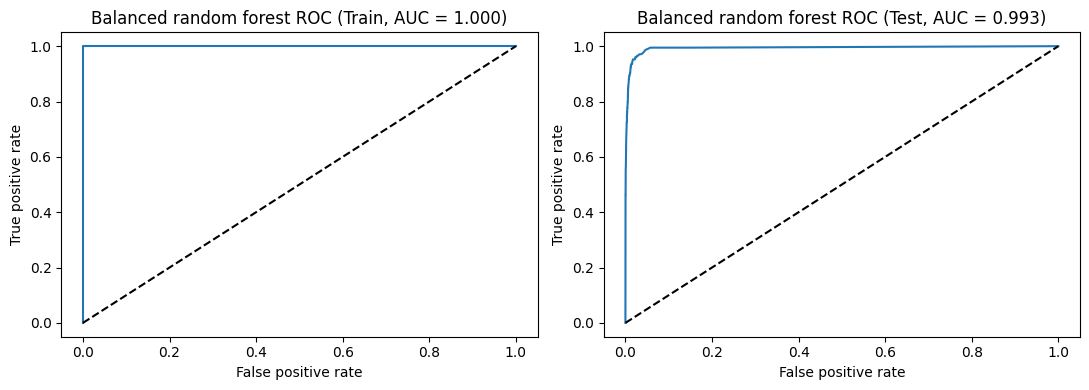

OOB error estimate: 0.0075 | test error: 0.0111


In [10]:
rf_bal = RandomForestClassifier(n_estimators=300, oob_score=True, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=0)
rf_bal.fit(X_train, y_train)
rf_bal_res = evaluate(rf_bal, "Balanced random forest")
print("OOB error estimate:", round(1 - rf_bal.oob_score_, 4), "| test error:", round(rf_bal_res["Test"][1], 4))

Common ways to address imbalance in random forests are class weights (weighted trees and weighted voting), downsampling the majority class in each bootstrap sample (balanced random forest), oversampling the minority class (for example with SMOTE), and moving the decision threshold. I used class_weight="balanced_subsample". The test AUC is 0.9933 and the test error is 0.0111 (16 false positives, 161 false negatives, 214 true positives, recall 57%), and the OOB error is 0.0075. So in this experiment the weighted forest did not improve on the plain forest: it made slightly fewer false positives but missed more failures. A likely reason is that fully grown trees are already pure at the leaves, so class weights change the splits only a little. Of these options, resampling and threshold moving are likely to help more than weights alone.


### (e) XGBoost and Model Trees


   param_reg_alpha  mean_test_score  std_test_score
0              0.0         0.989599        0.004599
1              0.1         0.989398        0.005513
2              1.0         0.988882        0.004867
3              5.0         0.989736        0.004522
4             20.0         0.988321        0.005154
Best alpha: 5
XGBoost (L1) | Train: AUC = 0.9988 | misclassification = 0.0020
          pred neg  pred pos
true neg     58983        17
true pos       104       896
XGBoost (L1) | Test: AUC = 0.9959 | misclassification = 0.0082
          pred neg  pred pos
true neg     15602        23
true pos       108       267


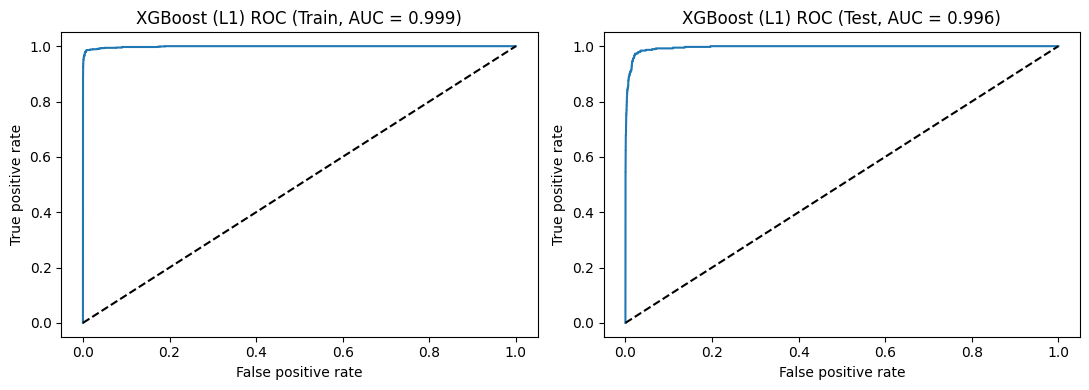

5-fold CV error: 0.0061 | test error: 0.0082


In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                    reg_lambda=0, tree_method="hist", eval_metric="logloss", n_jobs=-1, random_state=0)
alpha_grid = {"reg_alpha": [0, 0.1, 1, 5, 20]}
gs = GridSearchCV(xgb, alpha_grid, cv=skf, scoring="roc_auc", refit=True)
gs.fit(X_train, y_train)
print(pd.DataFrame(gs.cv_results_)[["param_reg_alpha", "mean_test_score", "std_test_score"]])
best_alpha = gs.best_params_["reg_alpha"]
print("Best alpha:", best_alpha)
xgb_best = gs.best_estimator_
xgb_res = evaluate(xgb_best, "XGBoost (L1)")
cv_pred = cross_val_predict(XGBClassifier(**{**xgb.get_params(), "reg_alpha": best_alpha}), X_train, y_train, cv=skf)
cv_err = 1 - accuracy_score(y_train, cv_pred)
print("5-fold CV error:", round(cv_err, 4), "| test error:", round(xgb_res["Test"][1], 4))

I used XGBoost with objective binary:logistic and the L1 penalty reg_alpha, chosen by 5-fold cross-validation on AUC. The CV AUC is very similar for all alphas (0.9883 to 0.9897, within one standard deviation), and alpha = 5 was best. The training AUC is 0.9988 with error 0.0020. The test AUC is 0.9959 with error 0.0082 (23 false positives, 108 false negatives, 267 true positives). The 5-fold CV error is 0.0061, lower than the test error of 0.0082, for the same reason as the OOB gap above: the test set has more positives. Among the three models so far, XGBoost has the best test AUC.


### (f) Use SMOTE to pre-process your data


   param_xgb__reg_alpha  mean_test_score  std_test_score
0                   0.0         0.987991        0.004610
1                   0.1         0.987097        0.004377
2                   1.0         0.986987        0.004984
3                   5.0         0.987129        0.004688
4                  20.0         0.986417        0.003848
Best alpha with SMOTE: 0
After SMOTE: negative = 59000 | positive = 59000
XGBoost (L1) + SMOTE | Train: AUC = 0.9989 | misclassification = 0.0041
          pred neg  pred pos
true neg     58805       195
true pos        53       947
XGBoost (L1) + SMOTE | Test: AUC = 0.9946 | misclassification = 0.0093
          pred neg  pred pos
true neg     15531        94
true pos        55       320


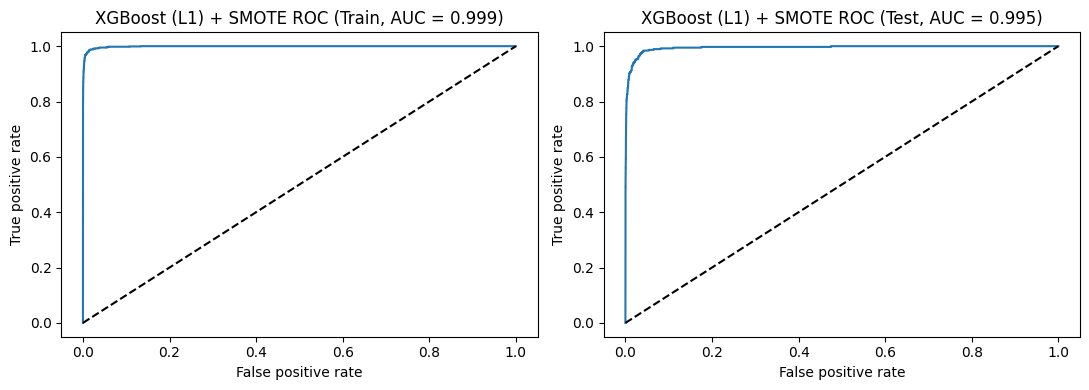

5-fold CV error (SMOTE inside each fold): 0.009 | test error: 0.0093
                 Model  Test AUC  Test error
         Random forest    0.9944      0.0075
Balanced random forest    0.9933      0.0111
          XGBoost (L1)    0.9959      0.0082
  XGBoost (L1) + SMOTE    0.9946      0.0093


In [13]:
smote_pipe = ImbPipeline([("smote", SMOTE(random_state=0)),
                          ("xgb", XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, subsample=0.8,
                                                colsample_bytree=0.8, reg_lambda=0, tree_method="hist",
                                                eval_metric="logloss", n_jobs=-1, random_state=0))])
gs_s = GridSearchCV(smote_pipe, {"xgb__reg_alpha": [0, 0.1, 1, 5, 20]}, cv=skf, scoring="roc_auc", refit=False)
gs_s.fit(X_train, y_train)
print(pd.DataFrame(gs_s.cv_results_)[["param_xgb__reg_alpha", "mean_test_score", "std_test_score"]])
best_alpha_s = gs_s.best_params_["xgb__reg_alpha"]
print("Best alpha with SMOTE:", best_alpha_s)

X_sm, y_sm = SMOTE(random_state=0).fit_resample(X_train, y_train)
print("After SMOTE: negative =", int((y_sm == 0).sum()), "| positive =", int((y_sm == 1).sum()))
xgb_smote = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                          reg_lambda=0, reg_alpha=best_alpha_s, tree_method="hist", eval_metric="logloss",
                          n_jobs=-1, random_state=0).fit(X_sm, y_sm)
smote_res = evaluate(xgb_smote, "XGBoost (L1) + SMOTE")

cv_err_s = []
for tr, va in skf.split(X_train, y_train):
    Xr, yr = SMOTE(random_state=0).fit_resample(X_train.iloc[tr], y_train[tr])
    m = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                      reg_lambda=0, reg_alpha=best_alpha_s, tree_method="hist", eval_metric="logloss",
                      n_jobs=-1, random_state=0).fit(Xr, yr)
    cv_err_s.append(1 - accuracy_score(y_train[va], m.predict(X_train.iloc[va])))
print("5-fold CV error (SMOTE inside each fold):", round(np.mean(cv_err_s), 4), "| test error:", round(smote_res["Test"][1], 4))

summary = pd.DataFrame({
    "Model": ["Random forest", "Balanced random forest", "XGBoost (L1)", "XGBoost (L1) + SMOTE"],
    "Test AUC": [rf_res["Test"][0], rf_bal_res["Test"][0], xgb_res["Test"][0], smote_res["Test"][0]],
    "Test error": [rf_res["Test"][1], rf_bal_res["Test"][1], xgb_res["Test"][1], smote_res["Test"][1]]})
print(summary.round(4).to_string(index=False))

SMOTE balances the training set to 59,000 negative and 59,000 positive examples. For cross-validation I used the right way: SMOTE is applied only to the training part of each fold, through an imblearn pipeline, and the validation fold is never oversampled. Oversampling before splitting would put synthetic copies of validation points into training and make the CV error look too good. The best alpha is 0 (CV AUC 0.9880). The test AUC is 0.9946 and the test error is 0.0093, with 94 false positives, 55 false negatives and 320 true positives (recall 85%). The 5-fold CV error (0.0090) is close to the test error (0.0093).

Comparison with the uncompensated XGBoost: SMOTE raises the misclassification rate slightly (0.0082 to 0.0093) and leaves the AUC about the same (0.9959 vs 0.9946), but it finds many more real failures (320 vs 267 of 375) at the price of more false alarms (94 vs 23). The data description gives a cost of 10 for an unnecessary check and 500 for a missed faulty truck. With those costs, the total costs on the test set are 51,180 for the random forest, 80,660 for the balanced forest, 54,230 for XGBoost and 28,440 for XGBoost with SMOTE. SMOTE is the best model under this cost metric (10 per false alarm, 500 per missed failure)


## 2. ISLR 6.6.3


(a) Steadily decreases. Increasing s relaxes the constraint, so the model gets more flexible and the training RSS can only go down.

(b) Decreases initially, then eventually increases, giving a U shape. A very small s underfits (high bias), and a very large s overfits (high variance).

(c) Steadily increases. A larger s gives a more flexible model, so the variance grows.

(d) Steadily decreases. A more flexible model has less bias.

(e) Remains constant. The irreducible error does not depend on the model.


## 3. ISLR 6.6.5


Since x11 = x12, x21 = x22, x11 + x21 = 0 and y1 + y2 = 0, we have x21 = x22 = -x11 and y2 = -y1, and the intercept estimate is zero.

(a) The ridge problem is to minimize (y1 - β1 x11 - β2 x12)² + (y2 - β1 x21 - β2 x22)² + λ(β1² + β2²).

(b) With the equalities above, the RSS equals 2(y1 - (β1 + β2) x11)², which depends only on the sum β1 + β2. For any fixed sum c, β1² + β2² ≥ c²/2, with equality exactly when β1 = β2. So the minimizer must have β1 = β2.

(c) The lasso problem is to minimize the same RSS + λ(|β1| + |β2|).

(d) The RSS again depends only on β1 + β2. For a fixed sum c, |β1| + |β2| ≥ |c|, with equality whenever β1 and β2 have the same sign. So the penalty is the same for every pair with that sum and the same sign. Every such pair is a solution, which is a whole line segment (β1 + β2 = c*, with both β ≥ 0 if c* > 0, or both ≤ 0 if c\* < 0), so the lasso solution is not unique.


## 4. ISLR 8.4.5


Majority vote: 6 of the 10 estimates (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) are above 0.5, so the class is Red. Average probability: (0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75) / 10 = 4.5 / 10 = 0.45, which is below 0.5, so the class is Green. The two approaches give different answers.


## 5. ISLR 9.7.3


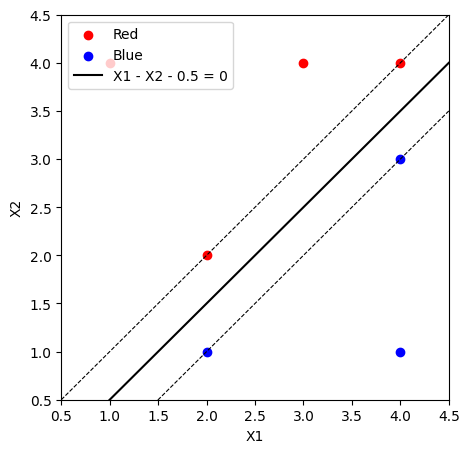

In [15]:
red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue = np.array([[2, 1], [4, 3], [4, 1]])
xs = np.linspace(0.5, 4.5, 50)
plt.figure(figsize=(5, 5))
plt.scatter(red[:, 0], red[:, 1], c="red", label="Red")
plt.scatter(blue[:, 0], blue[:, 1], c="blue", label="Blue")
plt.plot(xs, xs - 0.5, "k-", label="X1 - X2 - 0.5 = 0")
plt.plot(xs, xs, "k--", lw=0.8)
plt.plot(xs, xs - 1, "k--", lw=0.8)
plt.xlim(0.5, 4.5); plt.ylim(0.5, 4.5)
plt.xlabel("X1"); plt.ylabel("X2"); plt.legend(); plt.show()

(a) The plot shows the four Red points above and to the left of the three Blue points.

(b) The maximal margin hyperplane lies midway between (2,2), (4,4) and (2,1), (4,3): X1 - X2 - 0.5 = 0, so β0 = -0.5, β1 = 1, β2 = -1.

(c) Classify to Red if X1 - X2 - 0.5 < 0, and to Blue otherwise.

(d) The margin is the distance from (2,2) (or (2,1), (4,4), (4,3)) to the line: 0.5/√2 ≈ 0.354.

(e) The support vectors are observations 2, 3, 5 and 6, namely (2,2), (4,4), (2,1) and (4,3).

(f) A slight movement of observation 7, (4,1), would not change the maximal margin hyperplane, since it is not a support vector and lies away from the margin.

(g) A separating but not optimal hyperplane is X1 - X2 - 0.3 = 0, i.e. β0 = -0.3, β1 = 1, β2 = -1.

(h) Adding a Blue point at (2,3) makes the classes inseparable, because that point lies inside the triangle formed by the Red points (2,2), (1,4) and (3,4).
